A backtest answers one question: *if I had followed these rules in the past, what would have happened?* It sounds simple. In practice, a backtest is the easiest place in finance to fool yourself: one misplaced line can let tomorrow's price into today's decision, a forgotten cost can turn a loser into a winner, and trying enough variations will always find one that looks brilliant (Chapter 1).

In this project we build a backtester from scratch, line by line, with tests that catch the classic bugs. Then we use it on **time-series momentum** (trend following): buy assets whose price has been rising, sell those that have been falling. It is the strategy behind a large part of the managed-futures industry, and a published, well-documented effect (Moskowitz, Ooi and Pedersen, 2012), which makes it a good test of whether our engine reproduces known results honestly.

:::eli5
A backtest is a time machine with one rule: you may only look at yesterday's newspaper. Every morning you decide what to hold using only what you knew last night, then you live through the day and write down what you earned. If your time machine ever lets you peek at today's newspaper, your results are fiction.
:::

## Look at the big picture

### Frame the problem

We are a small systematic fund. The question: **does a simple, diversified trend-following strategy on liquid ETFs earn a return worth its risk after realistic costs, and would it have protected a stock portfolio in crashes?** The output is a research report with a go or no-go decision and, if go, a set of rules that could be traded from tomorrow.

### Select performance measures

| Measure | Formula / meaning | Why |
|---|---|---|
| Sharpe ratio | annualised mean excess return ÷ annualised volatility | return per unit of risk; comparable across strategies |
| Max drawdown | worst fall from a running peak | the pain investors actually feel |
| CAGR | $(\text{final}/\text{initial})^{1/\text{years}} - 1$ | compounded growth |
| Turnover | fraction of capital traded per year | drives costs |
| Crisis return | return in the worst months for stocks | the diversification case for trend following |
| Deflated Sharpe | Chapter 1 | is it luck, given how many variants we tried? |

### Check the assumptions

We trade once per month at the **close**, using a signal computed from closes **up to the previous day**; we pay a cost proportional to the value traded; we can go short and use modest leverage (as a futures-based fund can); idle cash earns the 3-month Treasury-bill rate. ETFs are a stand-in for futures: they are easy to download, but their histories are shorter.

## Get the data

Ten ETFs covering the main asset classes, adjusted for dividends (Yahoo Finance), and the 3-month T-bill rate (FRED).

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path
from scipy import stats
import json, time

mpl.rc("axes", labelsize=12, titlesize=13); mpl.rc("figure", dpi=110)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
DATA = Path("datasets")
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}

px = pd.read_csv(DATA / "etf_adjusted_close.csv", index_col="date", parse_dates=True)
tbill = pd.read_csv(DATA / "tbill_3m.csv", index_col="date", parse_dates=True)["DGS3MO"]
NAMES = {"SPY": "US stocks", "EFA": "developed ex-US stocks", "EEM": "emerging-market stocks",
         "TLT": "long Treasuries", "IEF": "7–10y Treasuries", "LQD": "corporate bonds",
         "GLD": "gold", "DBC": "commodities", "VNQ": "US real estate", "UUP": "US dollar"}
print(px.shape, px.index[0].date(), "→", px.index[-1].date())
print(px.apply(lambda s: s.first_valid_index().date()).to_string())

(5744, 10) 2004-01-02 → 2026-10-30
DBC    2006-02-06
EEM    2004-01-02
EFA    2004-01-02
GLD    2004-11-18
IEF    2004-01-02
LQD    2004-01-02
SPY    2004-01-02
TLT    2004-01-02
UUP    2007-03-01
VNQ    2004-09-29


### Clean and align

The ETFs start on different dates (the commodity and dollar funds launched in 2006 and 2007), the T-bill series has bond-market holidays, and we must check for bad ticks (Chapter 1).

In [2]:
rets = px.pct_change(fill_method=None)
print("largest absolute daily moves:")
print(rets.abs().max().sort_values(ascending=False).round(3).to_string())

rf_daily = (tbill.reindex(px.index).ffill() / 100) / 252        # annual % → daily decimal, holidays forward-filled
excess = rets.sub(rf_daily, axis=0)                              # returns in excess of cash
print("average T-bill rate:", f"{rf_daily.mean() * 252:.2%}")

largest absolute daily moves:
EEM    0.228
VNQ    0.195
EFA    0.159
SPY    0.145
GLD    0.113
LQD    0.098
DBC    0.079
TLT    0.075
UUP    0.041
IEF    0.034
average T-bill rate: 1.82%


The largest daily moves are real (2008 and March 2020), not data errors, so no cleaning is needed. From here on we work with **excess returns**: the return above cash. A futures position earns exactly the excess return, and the Sharpe ratio is defined on it.

## Discover the data: is there trend?

Before building a strategy, test the idea directly. If trends persist, an asset's return over the past year should predict the sign of its return next month. We scale each monthly return by the asset's volatility so that calm and wild assets count equally, exactly as Moskowitz, Ooi and Pedersen did.

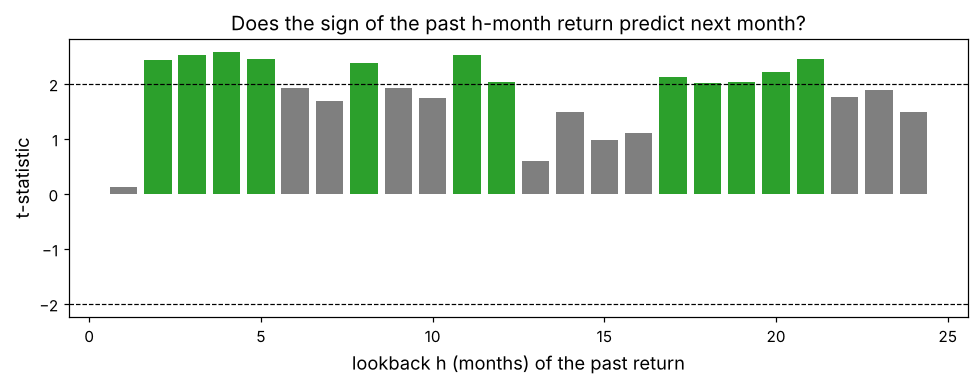

In [3]:
m_ex = (1 + excess).resample("ME").prod() - 1                    # monthly excess returns
d_vol = excess.ewm(com=60, min_periods=60).std() * np.sqrt(252)  # ex-ante annualised volatility (EWMA)
m_vol = d_vol.resample("ME").last()

def tstat_by_lookback(max_h=24):
    rows = []
    for h in range(1, max_h + 1):
        past = (1 + m_ex).rolling(h).apply(np.prod, raw=True) - 1             # past h-month excess return
        y = (m_ex / m_vol.shift(1)).stack()                                    # next month, vol-scaled
        x = np.sign(past.shift(1)).stack()                                     # known at the start of the month
        df = pd.concat([y, x], axis=1, keys=["y", "x"]).dropna()
        b = np.polyfit(df["x"], df["y"], 1)[0]
        resid = df["y"] - np.polyval(np.polyfit(df["x"], df["y"], 1), df["x"])
        se = resid.std() / (df["x"].std() * np.sqrt(len(df)))
        rows.append({"lookback": h, "slope": b, "t": b / se})
    return pd.DataFrame(rows).set_index("lookback")

tt = tstat_by_lookback()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(tt.index, tt["t"], color=["tab:green" if v > 2 else "tab:gray" for v in tt["t"]])
ax.axhline(2, color="k", ls="--", lw=0.8); ax.axhline(-2, color="k", ls="--", lw=0.8)
ax.set_xlabel("lookback h (months) of the past return"); ax.set_ylabel("t-statistic")
ax.set_title("Does the sign of the past h-month return predict next month?")
save_fig("trend_tstats"); plt.show()
R["t12"] = f"{tt.loc[12, 't']:.1f}"; R["tmax_h"] = int(tt["t"].idxmax()); R["tmax"] = f"{tt['t'].max():.1f}"

![Figure 2-1. Pooled over ten assets, the t-statistic of the slope when next month's volatility-scaled return is regressed on the sign of the past h-month return.](images/trend_tstats.png)

The 12-month lookback gives t = 2.0; the strongest is h = 4 months (t = 2.6). Two cautions from Chapter 1 apply immediately: the observations of different assets in the same month are correlated (a crisis hits them all), so these pooled t-statistics overstate the evidence; and we looked at 24 lookbacks, so the best one is flattered by selection. We will pick the lookback in a way that does not use this chart.

## Build the backtester

### The timing rule, written down

:::math
Let $w_t$ be the target weights decided with information up to the **close of day $t$**, and $r_{t+1}$ the excess returns from close $t$ to close $t+1$. The strategy's gross excess return on day $t + 1$ is

$$R^{\text{strat}}_{t+1} = \sum_i w_{i,t}\, r_{i,t+1},$$

and its net return subtracts costs proportional to the value traded, $c \sum_i |w_{i,t} - \tilde w_{i,t}|$, where $\tilde w_{i,t}$ is the weight the position had drifted to before trading (prices moved since the last rebalance). The single most important line of any backtest is therefore the **one-day lag** between deciding and earning.
:::

### Version 1: vectorised (fast, for research)

In [4]:
def backtest_vectorised(weights, excess, cost_bps=5.0):
    """weights[t] = target decided at close t (any frequency, forward-filled daily).
    Assumes we rebalance to target every day (no drift), so turnover is approximate."""
    w = weights.reindex(excess.index).ffill().fillna(0.0)
    held = w.shift(1).fillna(0.0)                               # decided yesterday, held today
    gross = (held * excess).sum(axis=1)
    turnover = held.diff().abs().sum(axis=1).fillna(0.0)
    return gross - turnover * cost_bps / 1e4

### Version 2: an event loop (exact drift, trades and costs)

Between rebalances, positions drift: an asset that rises becomes a larger share of the portfolio. The event loop tracks the actual dollar holdings, rebalances only on scheduled days, and charges costs on the trades it really makes.

In [5]:
def backtest_loop(targets, excess, rf_daily, rebalance_dates, cost_bps=5.0, capital=1.0):
    """targets: DataFrame of weights decided at the close of each rebalance date.
    Holdings are in dollars; cash earns rf. Returns a DataFrame of daily equity, turnover and costs."""
    dates, cols = excess.index, excess.columns
    rebal = set(rebalance_dates)
    tgt = targets.reindex(dates).ffill().fillna(0.0).to_numpy()
    r_ex = excess.fillna(0.0).to_numpy(); rf = rf_daily.reindex(dates).fillna(0.0).to_numpy()
    hold = np.zeros(len(cols)); equity = capital
    out = np.zeros((len(dates), 3))
    for t, d in enumerate(dates):
        # 1) earn today's return on yesterday's holdings (risky positions earn rf + excess; cash earns rf)
        pnl = hold @ r_ex[t] + equity * rf[t]
        hold = hold * (1 + r_ex[t] + rf[t])
        equity += pnl
        traded = cost = 0.0
        # 2) at today's close, rebalance to the target decided with data up to today
        if d in rebal:
            new_hold = tgt[t] * equity
            traded = np.abs(new_hold - hold).sum()
            cost = traded * cost_bps / 1e4
            hold = new_hold; equity -= cost
        out[t] = equity, traded / max(equity, 1e-12), cost
    return pd.DataFrame(out, index=dates, columns=["equity", "turnover", "cost"])

### Performance statistics

In [6]:
def perf(r, rf=None, periods=252):
    """r: daily excess returns (Series). Returns the key statistics."""
    r = r.dropna()
    eq = (1 + r).cumprod()
    years = len(r) / periods
    dd = eq / eq.cummax() - 1
    down = r[r < 0].std() * np.sqrt(periods)
    return pd.Series({
        "CAGR (excess)": eq.iloc[-1] ** (1 / years) - 1,
        "vol": r.std() * np.sqrt(periods),
        "Sharpe": r.mean() / r.std() * np.sqrt(periods),
        "Sortino": r.mean() * periods / down,
        "max DD": dd.min(),
        "Calmar": (eq.iloc[-1] ** (1 / years) - 1) / -dd.min(),
        "hit rate": (r > 0).mean(),
        "years": years,
    })

### Test the engine before trusting it

A backtester is software, and software needs tests. Four checks catch the bugs that matter most.

In [7]:
start = "2007-06-01"                     # all ten ETFs have data and the EWMA volatility is warmed up
ex = excess.loc[start:]
month_ends = ex.resample("ME").last().index
rebal_days = ex.index[ex.index.isin(ex.groupby(ex.index.to_period("M")).tail(1).index)]

# Test 1: 100% in SPY, rebalanced monthly, zero cost = buy and hold SPY (excess of cash)
w_spy = pd.DataFrame(0.0, index=rebal_days, columns=ex.columns); w_spy["SPY"] = 1.0
loop = backtest_loop(w_spy, ex, rf_daily, rebal_days, cost_bps=0)
strat_total = loop["equity"].iloc[-1] / loop["equity"].loc[rebal_days[0]]    # from the first rebalance on
bh_total = (1 + rets["SPY"].loc[rebal_days[0]:].iloc[1:]).prod()
print("Test 1  loop equity vs buy-and-hold SPY total return:", round(strat_total, 4), round(bh_total, 4))

# Test 2: the vectorised and loop engines agree (small gap = drift between monthly rebalances)
v = backtest_vectorised(w_spy, ex, cost_bps=0)
loop_ex = loop["equity"].pct_change().fillna(0) - rf_daily.reindex(ex.index).fillna(0)
print("Test 2  correlation of daily returns, vectorised vs loop:", round(v.corr(loop_ex), 5))

# Test 3: random long/short signals earn ~0 on average before costs and lose after costs
rng = np.random.default_rng(0)
sh0, sh20 = [], []
for seed in range(30):
    rand_w = pd.DataFrame(rng.choice([-0.1, 0.1], size=(len(rebal_days), ex.shape[1])), index=rebal_days, columns=ex.columns)
    sh0.append(perf(backtest_vectorised(rand_w, ex, 0))["Sharpe"]); sh20.append(perf(backtest_vectorised(rand_w, ex, 20))["Sharpe"])
print(f"Test 3  30 random signals: mean Sharpe {np.mean(sh0):+.2f} (sd {np.std(sh0):.2f}) at 0 bps, {np.mean(sh20):+.2f} at 20 bps")

# Test 4: a look-ahead canary. The signal "sign of this month's return", known at the month end, is a
# legitimate (weak) 1-month momentum signal if it is traded NEXT month. Back-filled into the same month,
# every day "knows" how its own month will end: that is the classic bfill bug.
m_ex_d = m_ex.loc[start:]
same_month = np.sign(m_ex_d) * 0.1
same_month.index = same_month.index.map(lambda d: ex.index[ex.index <= d][-1])
honest = backtest_vectorised(same_month, ex)                          # forward-filled and lagged: tradable
w_bug = same_month.reindex(ex.index).bfill()                          # each day sees its month's future
bug = (w_bug * ex).sum(axis=1)                                         # ...and no one-day lag
print("Test 4  Sharpe of a look-ahead signal: honest pipeline", round(perf(honest)["Sharpe"], 2), "| buggy pipeline", round(perf(bug)["Sharpe"], 2))
R["bug_sharpe"] = f"{perf(bug)['Sharpe']:.1f}"

Test 1  loop equity vs buy-and-hold SPY total return: 7.1419 7.1419
Test 2  correlation of daily returns, vectorised vs loop: 1.0


Test 3  30 random signals: mean Sharpe +0.01 (sd 0.21) at 0 bps, -0.38 at 20 bps
Test 4  Sharpe of a look-ahead signal: honest pipeline 0.04 | buggy pipeline 3.75


The engine reproduces buy-and-hold exactly, the two versions agree, a random signal earns nothing before costs and loses after them, and the look-ahead canary shows what a timing bug does: a Sharpe ratio of 3.7, which no real strategy has ever had. **If your backtest ever shows a Sharpe ratio above 3 on daily data, assume a bug until proven otherwise.**

:::trap
The three most common look-ahead bugs: (1) using today's close to compute a signal and also earning today's return; (2) filling gaps with `bfill()` or `interpolate()`; (3) using data that was revised or published later (index membership, fundamentals, economic data). The first two are caught by the lag in the engine and Test 4; the third needs point-in-time data (`merge_asof`, Toolkit 2).
:::

## A first strategy: the 200-day moving average on SPY

The simplest trend rule: hold the stock market when its price is above its 200-day moving average, otherwise hold cash.

                   CAGR (excess)    vol  Sharpe  Sortino  max DD  Calmar  \
200-day MA timing          0.062  0.116   0.578    0.656  -0.227   0.274   
buy and hold SPY           0.088  0.189   0.539    0.662  -0.562   0.156   

                   hit rate   years  
200-day MA timing     0.442  21.794  
buy and hold SPY      0.547  21.794  
switches per year: 6.1


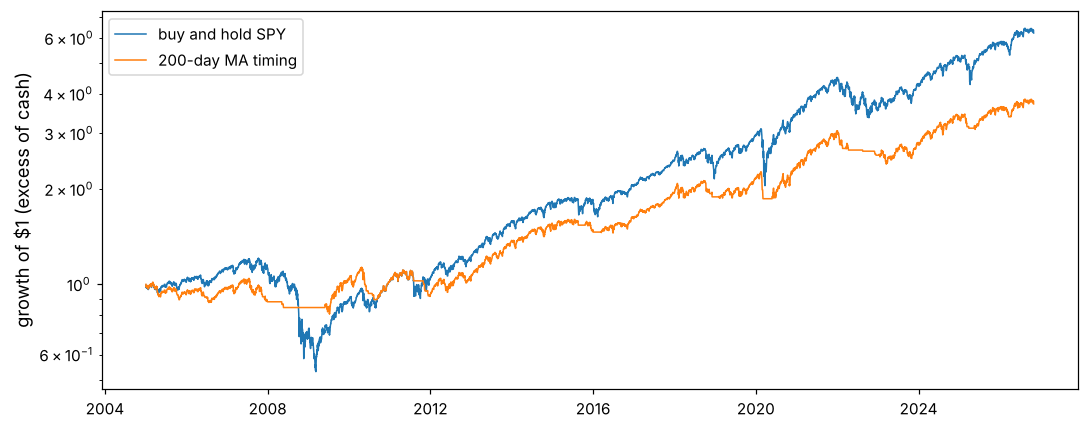

In [8]:
spy_px = px["SPY"]
above = (spy_px > spy_px.rolling(200).mean()).astype(float)       # decided at today's close
ma_ret = backtest_vectorised(above.to_frame("SPY").reindex(columns=ex.columns, fill_value=0.0), excess.loc["2005":], cost_bps=5)
bh = excess["SPY"].loc["2005":]
table = pd.DataFrame({"200-day MA timing": perf(ma_ret), "buy and hold SPY": perf(bh)}).T
print(table.round(3))
switches = above.loc["2005":].diff().abs().sum() / (len(above.loc["2005":]) / 252)
print(f"switches per year: {switches:.1f}")
R["ma_sh"] = f"{table.loc['200-day MA timing', 'Sharpe']:.2f}"; R["bh_sh"] = f"{table.loc['buy and hold SPY', 'Sharpe']:.2f}"
R["ma_dd"] = f"{table.loc['200-day MA timing', 'max DD']:.0%}"; R["bh_dd"] = f"{table.loc['buy and hold SPY', 'max DD']:.0%}"

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot((1 + bh).cumprod(), lw=1, label="buy and hold SPY")
ax.plot((1 + ma_ret).cumprod(), lw=1, label="200-day MA timing")
ax.set_yscale("log"); ax.legend(); ax.set_ylabel("growth of $1 (excess of cash)")
save_fig("ma200"); plt.show()

![Figure 2-2. The 200-day moving-average rule on SPY against buy and hold, in excess of cash.](images/ma200.png)

The rule's Sharpe ratio is 0.58 against 0.54 for buy and hold, with a maximum drawdown of -23% instead of -56%. Its main benefit is risk control: it stepped aside during the long declines of 2008 and 2022, but it also suffered “whipsaws”, buying back after a quick rebound and selling again. One asset, one rule and one parameter cannot tell us much; we need diversification and a fair test.

## The main strategy: diversified time-series momentum

### Rules

1. At each month end, for every asset compute the past 12-month excess return. The signal is its sign: $s_i = +1$ (long) if positive, $-1$ (short) if negative.
2. Size each position so that each asset contributes the same risk: weight $w_i = s_i \cdot \dfrac{\sigma^*}{\hat\sigma_i} \cdot \dfrac1N$, with $\hat\sigma_i$ the ex-ante volatility (EWMA, 60-day centre of mass) and $\sigma^* = 40\%$ as in Moskowitz, Ooi and Pedersen. Each position then targets 40%/N = 4% volatility on its own; how volatile the whole portfolio is depends on how correlated the positions are.
3. Cap the total gross leverage at 3 and pay 5 basis points per dollar traded.

In [9]:
def tsmom_targets(m_ex, m_vol, lookback=12, sigma_target=0.40, max_gross=3.0):
    past = (1 + m_ex).rolling(lookback).apply(np.prod, raw=True) - 1
    sig = np.sign(past)
    n_active = sig.notna().sum(axis=1).replace(0, np.nan)
    w = sig * (sigma_target / m_vol)
    w = w.div(n_active, axis=0)
    gross = w.abs().sum(axis=1)
    w = w.mul(np.minimum(1.0, max_gross / gross), axis=0)        # leverage cap
    return w.fillna(0.0)

def month_end_to_trading_day(w, index):
    """Move month-end labels to the last trading day of that month."""
    w = w.copy()
    w.index = [index[index <= d][-1] for d in w.index]
    return w

targets = month_end_to_trading_day(tsmom_targets(m_ex, m_vol).loc[start:], ex.index)
bt = backtest_loop(targets, ex, rf_daily, targets.index, cost_bps=5)
ts_ret = bt["equity"].pct_change().fillna(0) - rf_daily.reindex(ex.index).fillna(0)
spy_ex = ex["SPY"]
res = pd.DataFrame({"TSMOM (10 ETFs)": perf(ts_ret), "buy and hold SPY": perf(spy_ex),
                    "60/40 SPY/IEF": perf(0.6 * ex["SPY"] + 0.4 * ex["IEF"])}).T
print(res.round(3))
print(f"average turnover: {bt['turnover'].sum() / res.loc['TSMOM (10 ETFs)', 'years']:.1f}x capital per year;"
      f" total costs {bt['cost'].sum():.2%} of initial capital")
R.update(ts_sh=f"{res.iloc[0]['Sharpe']:.2f}", ts_vol=f"{res.iloc[0]['vol']:.0%}", ts_dd=f"{res.iloc[0]['max DD']:.0%}",
         spy_sh=f"{res.iloc[1]['Sharpe']:.2f}", spy_dd=f"{res.iloc[1]['max DD']:.0%}",
         corr_spy=f"{ts_ret.corr(spy_ex):+.2f}",
         turnover=f"{bt['turnover'].sum() / res.loc['TSMOM (10 ETFs)', 'years']:.1f}")

                  CAGR (excess)    vol  Sharpe  Sortino  max DD  Calmar  \
TSMOM (10 ETFs)           0.048  0.163   0.369    0.501  -0.425   0.113   
buy and hold SPY          0.089  0.197   0.532    0.655  -0.562   0.158   
60/40 SPY/IEF             0.066  0.113   0.619    0.784  -0.328   0.200   

                  hit rate   years  
TSMOM (10 ETFs)      0.529  19.389  
buy and hold SPY     0.546  19.389  
60/40 SPY/IEF        0.547  19.389  
average turnover: 10.1x capital per year; total costs 21.27% of initial capital


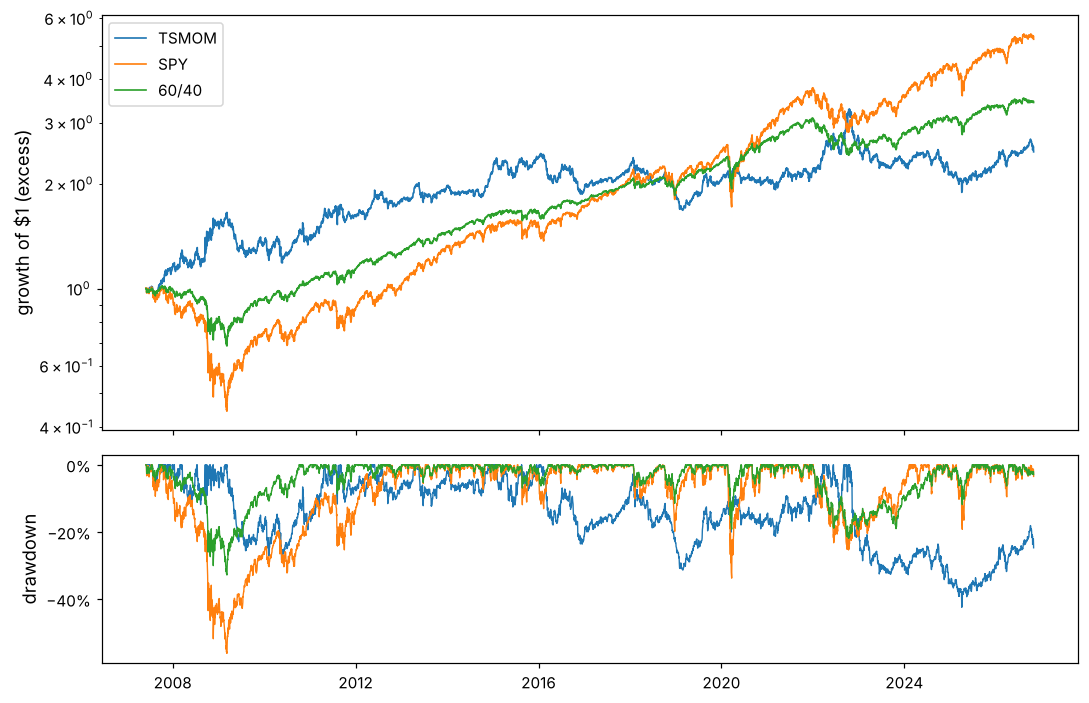

In [10]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for r_, lab in [(ts_ret, "TSMOM"), (spy_ex, "SPY"), (0.6 * ex["SPY"] + 0.4 * ex["IEF"], "60/40")]:
    eq = (1 + r_).cumprod(); ax[0].plot(eq, lw=1.1, label=lab)
    ax[1].plot(eq / eq.cummax() - 1, lw=0.9, label=lab)
ax[0].set_yscale("log"); ax[0].legend(); ax[0].set_ylabel("growth of $1 (excess)")
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax[1].set_ylabel("drawdown")
save_fig("tsmom_equity"); plt.show()

![Figure 2-3. Diversified time-series momentum against SPY and a 60/40 portfolio, net of 5 bps costs, in excess of cash. Bottom: drawdowns.](images/tsmom_equity.png)

Net of costs, the strategy has a Sharpe ratio of 0.37 at 16% volatility, a maximum drawdown of -42%, and a correlation of -0.08 with SPY. That is a lower Sharpe ratio than simply holding SPY (0.53) or a 60/40 portfolio (0.62) over this period, which was one of the best ever for stocks and bonds. It trades about 10.1 times its capital per year, mostly because volatility scaling changes position sizes every month. Before judging the number, look at *when* it made and lost money.

### Where does the return come from?

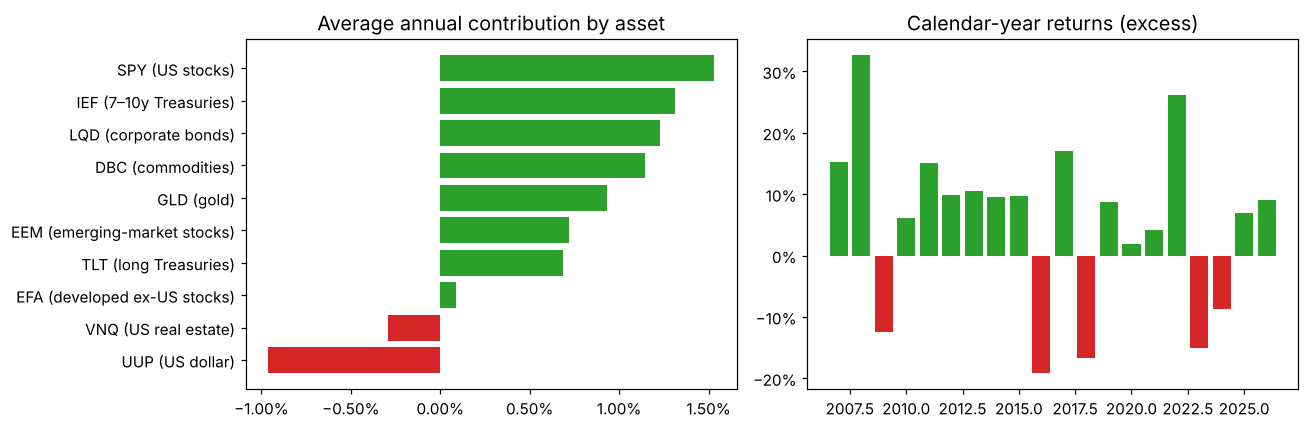

In [11]:
contrib = pd.DataFrame(index=ex.index, columns=ex.columns, dtype=float)
w_daily = targets.reindex(ex.index).ffill().shift(1).fillna(0)
contrib = (w_daily * ex).loc[start:]
by_asset = (contrib.sum() / (len(contrib) / 252)).sort_values()
by_year = ts_ret.groupby(ts_ret.index.year).apply(lambda x: (1 + x).prod() - 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].barh([f"{t} ({NAMES[t]})" for t in by_asset.index], by_asset, color=["tab:red" if v < 0 else "tab:green" for v in by_asset])
ax[0].xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax[0].set_title("Average annual contribution by asset")
ax[1].bar(by_year.index, by_year, color=["tab:red" if v < 0 else "tab:green" for v in by_year])
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax[1].set_title("Calendar-year returns (excess)")
save_fig("attribution"); plt.show()
R["best_year"] = int(by_year.idxmax()); R["best_year_ret"] = f"{by_year.max():.0%}"
R["n_neg_years"] = int((by_year < 0).sum()); R["n_years_tot"] = len(by_year)

![Figure 2-4. Left: average contribution of each asset to the annual excess return. Right: calendar-year returns. Trend following earns in a few large trends and gives back in choppy years.](images/attribution.png)

The best year was 2008 (33%), and 5 of the 20 calendar years were negative. That lumpy pattern is typical: trend following makes most of its money in a few persistent moves (falling stocks and rising bonds in 2008, rising rates and the dollar in 2022) and loses steadily in markets that reverse often.

### Crisis alpha: does it protect a stock portfolio?

            SPY  TSMOM
SPY                   
worst 20% -5.86   1.52
2         -0.88  -0.33
3          1.29   0.58
4          3.02   1.46
best 20%   6.49  -0.77


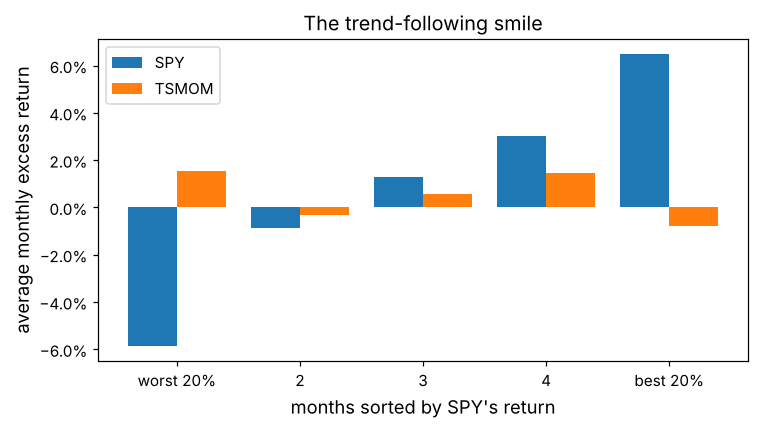

In [12]:
mo_spy = (1 + spy_ex).resample("ME").prod() - 1
mo_ts = (1 + ts_ret).resample("ME").prod() - 1
q = pd.qcut(mo_spy, 5, labels=["worst 20%", "2", "3", "4", "best 20%"])
smile = pd.DataFrame({"SPY": mo_spy.groupby(q, observed=True).mean(), "TSMOM": mo_ts.groupby(q, observed=True).mean()})
print((smile * 100).round(2))
fig, ax = plt.subplots(figsize=(7, 4))
x_ = np.arange(5)
ax.bar(x_ - 0.2, smile["SPY"], 0.4, label="SPY"); ax.bar(x_ + 0.2, smile["TSMOM"], 0.4, label="TSMOM")
ax.set_xticks(x_, smile.index); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("months sorted by SPY's return"); ax.set_ylabel("average monthly excess return"); ax.legend()
ax.set_title("The trend-following smile")
save_fig("smile"); plt.show()
R["smile_worst"] = f"{smile.loc['worst 20%', 'TSMOM']:+.1%}"; R["smile_worst_spy"] = f"{smile.loc['worst 20%', 'SPY']:+.1%}"
sixty = 0.6 * ex["SPY"] + 0.4 * ex["IEF"]
mo_60 = (1 + sixty).resample("ME").prod() - 1
R["sixty_worst"] = f"{mo_60.groupby(q, observed=True).mean().loc['worst 20%']:+.1%}"
R["sixty_sh"] = f"{perf(sixty)['Sharpe']:.2f}"; R["sixty_dd"] = f"{perf(sixty)['max DD']:.0%}"; R["sixty_corr"] = f"{sixty.corr(spy_ex):+.2f}"
R["mix_sh"] = f"{perf(0.5 * ts_ret + 0.5 * spy_ex)['Sharpe']:.2f}"

![Figure 2-5. Average monthly returns when SPY’s months are sorted into fifths. The “smile” means the strategy tends to do well in the extremes.](images/smile.png)

In the worst fifth of months for stocks (average -5.9%), the strategy averaged +1.5%. This is the classic argument for trend following: not a high Sharpe ratio on its own, but a tendency to earn when a stock portfolio suffers most.

## Fine-tune the strategy, honestly

### A parameter sweep, and the price of choosing

In [13]:
lookbacks = [1, 2, 3, 6, 9, 12, 18]
sweep = {}
for L in lookbacks:
    tg = month_end_to_trading_day(tsmom_targets(m_ex, m_vol, lookback=L).loc[start:], ex.index)
    b = backtest_loop(tg, ex, rf_daily, tg.index, cost_bps=5)
    sweep[L] = b["equity"].pct_change().fillna(0) - rf_daily.reindex(ex.index).fillna(0)
sweep = pd.DataFrame(sweep)
sw = sweep.apply(perf).T[["Sharpe", "vol", "max DD"]]
print(sw.round(3))

def deflated_sharpe(r_best, trial_returns):
    gamma = 0.5772156649
    per = trial_returns.mean() / trial_returns.std()
    N = trial_returns.shape[1]
    sr_star = per.std(ddof=1) * ((1 - gamma) * stats.norm.ppf(1 - 1 / N) + gamma * stats.norm.ppf(1 - 1 / (N * np.e)))
    x = r_best.dropna().to_numpy(); sr = x.mean() / x.std(ddof=1)
    g3, g4 = stats.skew(x), stats.kurtosis(x, fisher=False)
    return stats.norm.cdf((sr - sr_star) * np.sqrt(len(x) - 1) / np.sqrt(1 - g3 * sr + (g4 - 1) / 4 * sr**2))

best_L = sw["Sharpe"].idxmax()
R["best_L"] = int(best_L); R["best_L_sh"] = f"{sw.loc[best_L, 'Sharpe']:.2f}"
R["dsr"] = f"{deflated_sharpe(sweep[best_L], sweep):.2f}"
R["corr_lb"] = f"{sweep.corr().values[np.triu_indices(len(lookbacks), 1)].mean():.2f}"

    Sharpe    vol  max DD
1    0.000  0.173  -0.520
2    0.302  0.171  -0.444
3    0.384  0.178  -0.411
6    0.337  0.170  -0.475
9    0.294  0.170  -0.397
12   0.369  0.163  -0.425
18   0.354  0.160  -0.341


The best lookback in hindsight is 3 months (Sharpe 0.38), barely above 12 months, and the 1-month rule earns nothing. The deflated Sharpe ratio of the winner, accounting for the seven lookbacks we tried, is 0.81: no proof of skill at the usual 95% level. The variants are related (average pairwise correlation 0.50), so seven trials are fewer than seven independent chances. The point is the habit: report the trials, not only the winner.

:::quant
Practitioners rarely pick one lookback. They **average across lookbacks** (for example 1, 3 and 12 months), which is more robust than betting on the in-sample winner and costs little in expected performance. Try it in Exercise 2.
:::

### Walk-forward: choosing the parameter without peeking

In a **walk-forward** test, at the start of each year we choose the lookback that had the best Sharpe ratio over the *previous five years* and trade it for the next year. Every decision uses only past data, so the result is a genuine out-of-sample test of the selection procedure.

In [14]:
years = sorted(set(sweep.index.year))
wf_parts, chosen = [], {}
for y in years:
    hist = sweep.loc[str(y - 5):str(y - 1)]
    if len(hist) < 252 * 3:
        continue
    pick = (hist.mean() / hist.std()).idxmax()
    chosen[y] = pick
    wf_parts.append(sweep.loc[str(y), pick])
wf = pd.concat(wf_parts)
fixed12 = sweep[12].loc[wf.index]
cmp_wf = pd.DataFrame({"walk-forward choice": perf(wf), "fixed 12 months": perf(fixed12), "best in hindsight": perf(sweep[best_L].loc[wf.index])}).T
print(cmp_wf[["Sharpe", "vol", "max DD"]].round(3)); print("lookback chosen each year:", chosen)
R["wf_sh"] = f"{cmp_wf.loc['walk-forward choice', 'Sharpe']:.2f}"; R["fx_sh"] = f"{cmp_wf.loc['fixed 12 months', 'Sharpe']:.2f}"
R["hs_sh"] = f"{cmp_wf.loc['best in hindsight', 'Sharpe']:.2f}"

                     Sharpe    vol  max DD
walk-forward choice   0.159  0.164  -0.482
fixed 12 months       0.314  0.146  -0.425
best in hindsight     0.219  0.168  -0.411
lookback chosen each year: {2011: np.int64(3), 2012: np.int64(3), 2013: np.int64(3), 2014: np.int64(3), 2015: np.int64(18), 2016: np.int64(12), 2017: np.int64(18), 2018: np.int64(18), 2019: np.int64(2), 2020: np.int64(2), 2021: np.int64(2), 2022: np.int64(2), 2023: np.int64(6), 2024: np.int64(6), 2025: np.int64(9), 2026: np.int64(9)}


Over the same years, the walk-forward procedure earned a Sharpe ratio of 0.16, the fixed 12-month rule 0.31, and the lookback that looks best over the whole sample (3 months) only 0.22. Two lessons. First, **chasing the recently best parameter made things worse**: which lookback works best changes from period to period, so picking last period's winner mostly adds noise and turnover. Second, the full-sample winner was a winner partly because of the years before 2011; in the later years it lost to the plain default. Fixing a sensible parameter in advance, from theory and published evidence, beat optimisation.

### Costs: how much can the strategy afford?

In [15]:
cost_grid = [0, 5, 10, 20, 40, 80]
cost_sh = {}
for c in cost_grid:
    b = backtest_loop(targets, ex, rf_daily, targets.index, cost_bps=c)
    cost_sh[c] = perf(b["equity"].pct_change().fillna(0) - rf_daily.reindex(ex.index).fillna(0))["Sharpe"]
cost_sh = pd.Series(cost_sh)
print(cost_sh.round(3))
slope = np.polyfit(cost_sh.index, cost_sh.values, 1)
R["breakeven"] = f"{-slope[1] / slope[0]:.0f}"

0     0.400
5     0.369
10    0.338
20    0.276
40    0.152
80   -0.091
dtype: float64


Each extra basis point of cost lowers the Sharpe ratio by a roughly constant amount; extrapolating, the strategy breaks even at about 65 basis points per trade. Liquid ETFs cost one to five basis points to trade for a small fund, so costs matter but do not kill this strategy. Strategies that trade daily are a different story: there the cost line is ten to twenty times steeper.

## Is it luck?

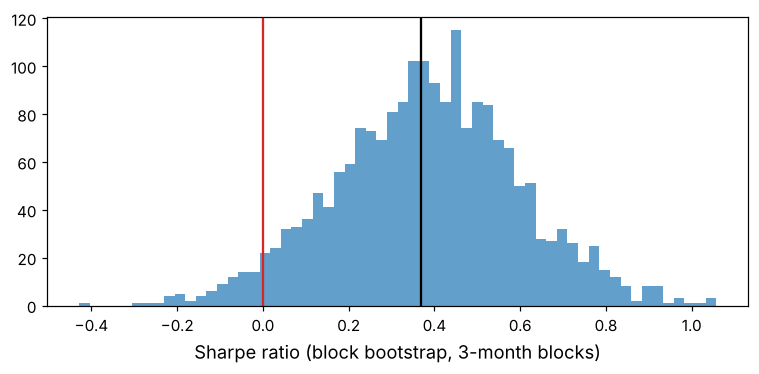

In [16]:
def block_bootstrap_sharpe(r, B=2000, block=63, seed=1):
    rng_ = np.random.default_rng(seed); x = r.dropna().to_numpy(); n = len(x)
    nb = int(np.ceil(n / block)); out = np.empty(B)
    for b in range(B):
        idx = (rng_.integers(0, n - block, nb)[:, None] + np.arange(block)).ravel()[:n]
        s = x[idx]; out[b] = s.mean() / s.std() * np.sqrt(252)
    return out

boot = block_bootstrap_sharpe(ts_ret)
lo, hi = np.percentile(boot, [2.5, 97.5])
R["ci"] = f"[{lo:.2f}, {hi:.2f}]"; R["p_pos"] = f"{(boot > 0).mean():.0%}"
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(boot, bins=60, alpha=0.7); ax.axvline(0, color="tab:red"); ax.axvline(perf(ts_ret)["Sharpe"], color="k")
ax.set_xlabel("Sharpe ratio (block bootstrap, 3-month blocks)"); save_fig("bootstrap"); plt.show()

![Figure 2-6. The block-bootstrap distribution of the strategy’s Sharpe ratio. The black line is the estimate, red is zero.](images/bootstrap.png)

The 95% bootstrap interval for the Sharpe ratio is [-0.05, 0.80], and 96% of the bootstrap samples are positive. With about nineteen years of data, that is the honest summary: consistent with a modest positive premium, far from proof of a large one. The long academic record (trend following has been documented over more than a century of futures data, by Hurst, Ooi and Pedersen) is stronger evidence than our ETF sample.

## Present your solution

| | TSMOM (10 ETFs) | SPY | 60/40 |
|---|---|---|---|
| Sharpe (net of 5 bps) | 0.37 | 0.53 | 0.62 |
| Max drawdown | -42% | -56% | -33% |
| Correlation with SPY | -0.08 | 1 | +0.97 |
| Average month in SPY's worst fifth | +1.5% | -5.9% | -3.3% |
| 50/50 with SPY: Sharpe | 0.67 | | |

**Recommendation.** As a stand-alone investment the evidence is weak in this sample: a Sharpe ratio of 0.37 with a bootstrap interval that includes zero. As a **diversifier** it is attractive, because it earned in the months stocks suffered most: a 50/50 mix with SPY has a Sharpe ratio of 0.67. The short positions lost money over this period (Exercise 4: the long-only version scores higher but is more correlated with stocks), which is a known feature of an era when stocks and bonds mostly rose. If we trade it: fix the rules now (12-month or averaged lookbacks, 40% per-asset volatility scaling, monthly rebalancing), size the allocation for its drawdowns, and evaluate live results against the bootstrap interval rather than against the backtest's point estimate.

## Launch, monitor and maintain

- **Freeze the code and parameters** before trading. Store the git commit hash with every live trade list.
- **Reconcile weekly**: live returns against the backtest of the same days. Gaps reveal bad data, missed trades or costs you did not model.
- **Alarm levels**: set in advance a drawdown that triggers a review (for example 1.5 times the worst backtest drawdown), so that you do not abandon the strategy in a normal bad year or ignore a broken one.
- **Paper-trade first** for a few months (Chapter 10 builds the loop).

## Try it out

::playground animations/trend_lab.html 960

The playground runs the same strategy in your browser on the real monthly data: change the lookback, the volatility target, the cost and the asset list, and see the equity curve, drawdown and statistics update. Try to find a setting that looks much better than the default; then remember Chapter 1.

## Exercises

:::exercise
1. Replace the sign signal with a *continuous* signal, the past 12-month return divided by its volatility and clipped to [−1, 1]. Does the Sharpe ratio or the turnover improve?
2. Average the target weights of the 1-, 3- and 12-month lookbacks. Compare its Sharpe ratio and drawdown with each single lookback.
3. Add a **no-trade buffer**: rebalance an asset only when its target weight differs from its current weight by more than 20% of the target. How much turnover and cost does it save?
4. Run the strategy long-only (signals of −1 become 0). How do the Sharpe ratio and the crisis behaviour change?
5. Scale the whole portfolio each month to a 10% ex-ante volatility using the covariance of the past year. Report the realised volatility. (Chapter 3 improves the volatility forecast.)
:::

<details><summary>Solutions</summary>

In [17]:
# 1 continuous signal
past12 = (1 + m_ex).rolling(12).apply(np.prod, raw=True) - 1
cont = (past12 / m_vol).clip(-1, 1)
w_c = (cont * 0.40 / m_vol).div(cont.notna().sum(axis=1), axis=0).fillna(0)
w_c = w_c.mul(np.minimum(1, 3 / w_c.abs().sum(axis=1)), axis=0)
tg_c = month_end_to_trading_day(w_c.loc[start:], ex.index)
b_c = backtest_loop(tg_c, ex, rf_daily, tg_c.index)
print("continuous:", perf(b_c["equity"].pct_change().fillna(0) - rf_daily.reindex(ex.index).fillna(0))[["Sharpe", "max DD"]].round(3).to_dict(),
      "turnover/yr", round(b_c["turnover"].sum() / (len(ex) / 252), 1))

# 2 average of lookbacks
w_avg = sum(tsmom_targets(m_ex, m_vol, lookback=L) for L in [1, 3, 12]) / 3
tg_a = month_end_to_trading_day(w_avg.loc[start:], ex.index)
b_a = backtest_loop(tg_a, ex, rf_daily, tg_a.index)
print("averaged lookbacks:", perf(b_a["equity"].pct_change().fillna(0) - rf_daily.reindex(ex.index).fillna(0))[["Sharpe", "max DD"]].round(3).to_dict())

# 4 long-only
w_lo = tsmom_targets(m_ex, m_vol).clip(lower=0)
tg_lo = month_end_to_trading_day(w_lo.loc[start:], ex.index)
r_lo = backtest_loop(tg_lo, ex, rf_daily, tg_lo.index)["equity"].pct_change().fillna(0) - rf_daily.reindex(ex.index).fillna(0)
print("long-only:", perf(r_lo)[["Sharpe", "max DD"]].round(3).to_dict(), "corr with SPY", round(r_lo.corr(spy_ex), 2))

continuous: {'Sharpe': 0.308, 'max DD': -0.303} turnover/yr 10.0
averaged lookbacks: {'Sharpe': 0.327, 'max DD': -0.373}
long-only: {'Sharpe': 0.642, 'max DD': -0.233} corr with SPY 0.36


</details>

## What's next

We sized every position by an estimate of its volatility, using a simple exponential average. Chapter 3 asks how well volatility can be forecast, builds GARCH by maximum likelihood from scratch, compares it with machine-learning forecasts, and shows how better forecasts make volatility targeting work.

In [18]:
# export monthly data for the interactive playground
Path("animations").mkdir(exist_ok=True)
mx = m_ex.loc["2006-01":]; mv = m_vol.loc["2006-01":]
payload = {"dates": [d.strftime("%Y-%m") for d in mx.index], "assets": list(mx.columns), "names": NAMES,
           "ret": {c: [None if pd.isna(v) else round(float(v), 6) for v in mx[c]] for c in mx.columns},
           "vol": {c: [None if pd.isna(v) else round(float(v), 6) for v in mv[c]] for c in mv.columns}}
Path("animations/data.js").write_text("window.TREND_DATA = " + json.dumps(payload) + ";\n")
print("exported", len(mx), "months")

exported 250 months
